# Lumen-Aware Depth Calibration for Monocular Colonoscopy Depth

**Model:** Depth Anything V2 Small (DAv2), zero-shot, no training.
**Data:** C3VD. Development: `trans_t1_a` (61 frames). Test: `trans_t2_b`.

## Aim
DAv2 gives relative depth (disparity) only. This notebook converts its output to metric depth in millimetres.
We test if a calibration that knows where the dark, far lumen is gives a better result than one global calibration.

## Methods compared
| Step | Method | What it does |
|---|---|---|
| 0 | Constant median | Predicts the median dev depth everywhere (required baseline) |
| 1 | Global linear | depth = a · (−disparity) + b, one fit for all frames |
| 2 | Smooth correction | Adds a correction curve that depends on the linear depth |
| 3 | Lumen-aware | Uses two correction curves (wall and lumen), mixed by a soft lumen map *w* |
| 4 | Isotonic (log) | A monotonic correction curve, fitted in log-depth |
| 5 | Lumen-aware isotonic (log) | Two isotonic curves (wall and lumen), mixed by *w* (final method) |

## Evaluation
- **Development (trans_t1_a):** 4-fold **block** cross-validation on consecutive frames, with a gap of 2 frames between the fit and test blocks. We select all settings here.
- **Test (trans_t2_b):** all parameters are fitted on the 61 dev frames and are applied once, with no change.
- Valid pixels: inside the field of view, and ground truth between 0 and the 100 mm limit. Clipped pixels (ground truth at the limit) are **excluded**.
- Metrics: AbsRel, RMSE, MAE (mm) and δ < 1.25.

In [15]:
import sys; sys.path.insert(0, "..")
from common import *          # CFG, DEVICE, SEED, np, pd, torch, cv2, tifffile, Path and project helpers

import json
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display
from PIL import Image
from scipy import ndimage
from sklearn.isotonic import IsotonicRegression
from transformers import AutoModelForDepthEstimation
from tqdm import tqdm

# ---- Settings ----
RUN_NAME   = "Final_LumenAware_DAv2_Small"
MODEL_ID   = "depth-anything/Depth-Anything-V2-Small-hf"
MASK       = "exclude_clipped"                      # clipped ground-truth pixels are not used
INPUT_SIZE = (700, 868)                             # DAv2 input (H, W), multiples of 14. Selected on dev (Section 9)
DMAX       = 100.0                                  # ground-truth depth limit (mm)
BIN_EDGES  = np.array([0, 20, 40, 60, 80, 100], dtype=np.float32)
CENTERS    = (BIN_EDGES[:-1] + BIN_EDGES[1:]) / 2   # 10, 30, 50, 70, 90 mm
MIN_PIXELS = 2000                                   # minimum (weighted) pixels in a correction bin
FIT_STRIDE = 4                                      # fit on every 4th valid pixel (evaluation uses all)
ISO_STRIDE = 16                                     # same for the isotonic fits
N_BLOCKS, GAP = 4, 2                                # block cross-validation
CUES       = ["both", "dark", "far"]                # lumen cues
SIGMA, TAU = 20, 0.5                                # lumen detector settings (fixed, not fitted)
RANGES     = [(0, 20), (20, 40), (40, 60), (60, 100)]

out_dir = stream_results_dir(CFG, f"{RUN_NAME}_{MASK}")
fig_dir = out_dir / "figures"
fig_dir.mkdir(exist_ok=True)
dev_paths  = list_frames(CFG, "dev")                # trans_t1_a
test_paths = list_frames(CFG, "test")               # trans_t2_b

# ---- Methods: (label, kind, cue) ----
LIN, SMO, LUM = "DAv2 + global linear", "+ smooth correction", "+ lumen-aware (both cues)"
ISO, FINAL    = "Isotonic (log)", "Lumen-aware isotonic (log)"
METHODS = [
    ("Constant median",               "constant",  None),
    (LIN,                             "linear",    None),
    (SMO,                             "smooth",    None),
    ("+ lumen-aware (darkness only)", "lumen",     "dark"),
    ("+ lumen-aware (depth only)",    "lumen",     "far"),
    (LUM,                             "lumen",     "both"),
    (ISO,                             "iso",       None),
    (FINAL,                           "iso_lumen", "both"),
]
COLORS = {
    "Constant median": "#b5b5b5", LIN: "#8796b0", SMO: "#e0a030",
    "+ lumen-aware (darkness only)": "#a9cdb4", "+ lumen-aware (depth only)": "#6aa486",
    LUM: "#2e6f4e", ISO: "#9467bd", FINAL: "#4b2a7b",
}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(f"{len(dev_paths)} dev frames | {len(test_paths)} test frames | device {DEVICE} | mask {MASK} | input {INPUT_SIZE}")

61 dev frames | 103 test frames | device mps | mask exclude_clipped | input (700, 868)


In [16]:
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE).eval()
MEAN_I = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD_I  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


@torch.no_grad()
def predict_disp(rgb, size=INPUT_SIZE, flip=False):
    """DAv2 disparity at the original image size. flip=True averages with the mirrored image."""
    H, W = size
    img = np.asarray(Image.fromarray(rgb).resize((W, H), Image.BICUBIC), dtype=np.float32) / 255.0
    x = torch.from_numpy(((img - MEAN_I) / STD_I).transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    if flip:
        x = torch.cat([x, torch.flip(x, dims=[3])])
    d = model(pixel_values=x).predicted_depth
    if flip:
        d = 0.5 * (d[0:1] + torch.flip(d[1:2], dims=[2]))
    d = torch.nn.functional.interpolate(d.unsqueeze(1), size=rgb.shape[:2], mode="bilinear", align_corners=False)
    return d[0, 0].float().cpu().numpy()

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

In [17]:
def blur(x, sigma=SIGMA):
    return cv2.GaussianBlur(x.astype(np.float32), (0, 0), sigma)


def lumen_cues(rgb, depth_like, fov, sigma=SIGMA):
    """Darkness and depth cues in [0, 1]. depth_like: a larger value = farther."""
    f = fov.astype(np.float32)
    v = rgb.astype(np.float32).max(axis=2) / 255.0
    v_s = blur(v * f, sigma) / (blur(f, sigma) + 1e-6)          # no darkening at the black corners
    dark = 1.0 - np.clip(v_s / (np.percentile(v_s[fov], 99) + 1e-6), 0, 1)
    far = np.zeros_like(v_s)
    ranks = depth_like[fov].argsort().argsort()
    far[fov] = ranks / max(len(ranks) - 1, 1)
    far = blur(far * f, sigma) / (blur(f, sigma) + 1e-6)
    dark[~fov], far[~fov] = 0, 0
    return dark, far


def combine(dark, far, cue):
    return {"dark": dark, "far": far}.get(cue, np.sqrt(dark * far))


def lumen_from_score(score, fov, sigma=SIGMA, tau=TAU):
    """Soft lumen map w and the hard core (largest region above tau)."""
    mask = (score > tau) & fov
    lab, n = ndimage.label(mask)
    if n == 0:
        return np.zeros(score.shape, np.float16), np.zeros(score.shape, bool)
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    core = lab == (np.argmax(sizes) + 1)
    w = blur(core * score, sigma)
    w = w / (w.max() + 1e-6)
    w[~fov] = 0
    return w.astype(np.float16), core


def make_lumen_maps(F):
    """Compute the lumen map for each cue from the current prediction F['pred']."""
    dark, far = lumen_cues(F["rgb"], -F["pred"], F["fov"])
    F["w"] = {}
    for cue in CUES:
        F["w"][cue], core = lumen_from_score(combine(dark, far, cue), F["fov"])
        if cue == "both":
            F["core"] = core

In [18]:
def load_frames(paths, desc):
    out = []
    for cp in tqdm(paths, desc=desc):
        rgb = cv2.cvtColor(cv2.imread(str(cp)), cv2.COLOR_BGR2RGB)
        raw = tifffile.imread(cp.with_name(cp.name.replace("_color.png", "_depth.tiff")))
        fov = rgb.max(axis=2) > 10
        F = {"name": cp.stem.replace("_color", ""), "rgb": rgb,
             "gt": raw.astype(np.float32) / 65535.0 * DMAX,
             "fov": fov,
             "clipped": (raw == 65535) & fov,
             "valid": (raw > 0) & (raw < 65535) & fov,
             "pred": predict_disp(rgb)}
        make_lumen_maps(F)
        out.append(F)
    return out


FR = load_frames(dev_paths, "Dev frames")             # the test frames are loaded only in Section 8
BASE_PRED = [F["pred"].copy() for F in FR]            # keep for the sensitivity checks
print(f"Loaded {len(FR)} dev frames. Mean valid pixels: {np.mean([F['valid'].mean() for F in FR]) * 100:.1f}%")

Dev frames: 100%|██████████| 61/61 [00:32<00:00,  1.88it/s]


Loaded 61 dev frames. Mean valid pixels: 91.0%


In [19]:
def linear_depth(F, P):
    return np.clip(P["a"] * -F["pred"] + P["b"], 1e-3, DMAX)


def fit_params(ids):
    """Global linear fit and binned correction curves on the frames in ids."""
    xs, ys, ws = [], [], {c: [] for c in CUES}
    for i in ids:
        F, v = FR[i], FR[i]["valid"]
        xs.append(-F["pred"][v][::FIT_STRIDE])
        ys.append(F["gt"][v][::FIT_STRIDE])
        for c in CUES:
            ws[c].append(F["w"][c][v][::FIT_STRIDE])
    x = np.concatenate(xs).astype(np.float64)
    y = np.concatenate(ys).astype(np.float64)

    xm, ym = x.mean(), y.mean()
    a = ((x - xm) * (y - ym)).sum() / ((x - xm) ** 2).sum()
    b = ym - a * xm

    lin = np.clip(a * x + b, 1e-3, DMAX)
    err = y - lin
    k = np.clip(np.digitize(lin, BIN_EDGES) - 1, 0, len(CENTERS) - 1)

    def binned(weights):
        s = np.bincount(k, weights=err * weights, minlength=len(CENTERS))
        n = np.bincount(k, weights=weights, minlength=len(CENTERS))
        return s, n

    s, n = binned(np.ones_like(err))
    ok = n >= MIN_PIXELS
    curves = {"all": (CENTERS[ok], s[ok] / n[ok])}
    counts = {"all": n}
    fallback = np.interp(CENTERS, *curves["all"])
    for c in CUES:
        w = np.concatenate(ws[c]).astype(np.float64)
        for part, wt in [("wall", 1.0 - w), ("lumen", w)]:
            s, n = binned(wt)
            curves[f"{part}_{c}"] = (CENTERS, np.where(n >= MIN_PIXELS, s / np.maximum(n, 1e-9), fallback))
            counts[f"{part}_{c}"] = n
    return {"a": float(a), "b": float(b), "median": float(np.median(y)), "curves": curves, "counts": counts}


def fit_iso(ids, P, lumen=False):
    """Isotonic curve(s) from linear depth to log ground truth."""
    xs, ys, ws = [], [], []
    for i in ids:
        F, v = FR[i], FR[i]["valid"]
        xs.append(linear_depth(F, P)[v][::ISO_STRIDE])
        ys.append(F["gt"][v][::ISO_STRIDE])
        ws.append(F["w"]["both"][v][::ISO_STRIDE].astype(np.float32))
    x, y, w = map(np.concatenate, (xs, ys, ws))
    t = np.log(y)
    iso = lambda wt: IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x, t, sample_weight=wt)
    if not lumen:
        return {"all": iso(np.ones_like(x))}
    return {"wall": iso(1.0 - w + 1e-6), "lumen": iso(w + 1e-6)}


def fit_all(ids):
    P = fit_params(ids)
    P["iso"] = fit_iso(ids, P)
    P["iso_lumen"] = fit_iso(ids, P, lumen=True)
    return P


def predict(kind, F, P, cue="both"):
    if kind == "constant":
        return np.full(F["gt"].shape, P["median"], np.float32)
    lin = linear_depth(F, P)
    if kind == "linear":
        return lin
    if kind == "smooth":
        return np.clip(lin + np.interp(lin, *P["curves"]["all"]), 1e-3, DMAX)
    w = F["w"][cue].astype(np.float32)
    if kind == "lumen":
        corr = (1 - w) * np.interp(lin, *P["curves"][f"wall_{cue}"]) + w * np.interp(lin, *P["curves"][f"lumen_{cue}"])
        return np.clip(lin + corr, 1e-3, DMAX)
    flat, M = lin.ravel(), P[kind]
    if kind == "iso":
        t = M["all"].predict(flat)
    else:
        wf = w.ravel()
        t = (1 - wf) * M["wall"].predict(flat) + wf * M["lumen"].predict(flat)
    return np.clip(np.exp(t).reshape(lin.shape), 1e-3, DMAX)


def frame_metrics(pred, F, region=None):
    v = F["valid"] if region is None else (F["valid"] & region)
    if v.sum() < 100:
        return None
    p = np.clip(pred[v], 1e-3, None).astype(np.float64)
    g = F["gt"][v].astype(np.float64)
    e = p - g
    return {"absrel": np.mean(np.abs(e) / g), "mse": np.mean(e ** 2),
            "mae": np.mean(np.abs(e)), "delta1": np.mean(np.maximum(p / g, g / p) < 1.25)}

In [20]:
FOLDS = []
for test in dev_blocks(len(FR), N_BLOCKS):
    lo, hi = test.min() - GAP, test.max() + GAP
    FOLDS.append(([i for i in range(len(FR)) if i < lo or i > hi], list(test)))
HELD = {i: k for k, (_, te) in enumerate(FOLDS) for i in te}      # fold that holds out each frame


def evaluate(methods, with_train=True):
    fold_params = [fit_all(tr) for tr, _ in tqdm(FOLDS, desc="Fitting folds")]
    per_frame, tt_rows = [], []
    range_acc = {label: np.zeros((len(RANGES), 3)) for label, _, _ in methods}   # |err| sum, signed sum, count
    for k, (train, test) in enumerate(tqdm(FOLDS, desc="Evaluating")):
        P = fold_params[k]
        for label, kind, cue in methods:
            parts = [("held-out", test)] + ([("train", train)] if with_train else [])
            for part, ids in parts:
                absrels = []
                for i in ids:
                    F = FR[i]
                    pred = predict(kind, F, P, cue or "both")
                    m = frame_metrics(pred, F)
                    absrels.append(m["absrel"])
                    if part != "held-out":
                        continue
                    lumen_region = F["w"]["both"].astype(np.float32) > 0.5
                    ml, mw = frame_metrics(pred, F, lumen_region), frame_metrics(pred, F, ~lumen_region)
                    per_frame.append({"frame": F["name"], "idx": i, "fold": k + 1, "method": label, **m,
                                      "absrel_wall": mw["absrel"] if mw else np.nan,
                                      "absrel_lumen": ml["absrel"] if ml else np.nan})
                    v = F["valid"]
                    g, e = F["gt"][v], F["gt"][v] - pred[v]            # signed: + = prediction too near
                    for r, (lo_d, hi_d) in enumerate(RANGES):
                        sel = (g >= lo_d) & ((g < hi_d) if hi_d < DMAX else (g <= hi_d))
                        range_acc[label][r] += [np.abs(e[sel]).sum(), e[sel].sum(), sel.sum()]
                tt_rows.append({"method": label, "fold": k + 1, "part": part, "absrel": np.mean(absrels)})
    return pd.DataFrame(per_frame), pd.DataFrame(tt_rows), range_acc, fold_params


def summarise(per_frame):
    t = (per_frame.groupby("method", sort=False)
         .agg(absrel=("absrel", "mean"), mse=("mse", "mean"), mae=("mae", "mean"), delta1=("delta1", "mean"),
              absrel_wall=("absrel_wall", "mean"), absrel_lumen=("absrel_lumen", "mean"))
         .reset_index())
    t["rmse"] = np.sqrt(t.pop("mse"))
    fold_ab = per_frame.groupby(["method", "fold"]).absrel.mean().unstack()
    if SMO in fold_ab.index:
        better = fold_ab.lt(fold_ab.loc[SMO], axis=1).sum(axis=1)
        t["folds_better"] = t.method.map(better).astype(int)
    return t


per_frame, train_test, range_acc, FOLD_PARAMS = evaluate(METHODS)
abl = summarise(per_frame)
per_frame.to_csv(out_dir / "per_frame_heldout.csv", index=False)
train_test.to_csv(out_dir / "train_vs_heldout.csv", index=False)
abl.to_csv(out_dir / "ablation_heldout.csv", index=False)
print("Done.")

Evaluating: 100%|██████████| 4/4 [01:06<00:00, 16.57s/it]

Done.


In [21]:
COLS = {"method": "Method", "absrel": "AbsRel ↓", "rmse": "RMSE (mm) ↓", "mae": "MAE (mm) ↓",
        "delta1": "δ<1.25 ↑", "absrel_wall": "AbsRel wall ↓", "absrel_lumen": "AbsRel lumen ↓",
        "folds_better": f"Folds better than smooth (of {N_BLOCKS})"}
LOW  = ["AbsRel ↓", "RMSE (mm) ↓", "MAE (mm) ↓", "AbsRel wall ↓", "AbsRel lumen ↓"]


def show_table(df, title):
    d = df.rename(columns=COLS)
    styled = (d.style
              .format({c: "{:.3f}" for c in ["AbsRel ↓", "δ<1.25 ↑", "AbsRel wall ↓", "AbsRel lumen ↓"] if c in d} |
                      {c: "{:.2f}" for c in ["RMSE (mm) ↓", "MAE (mm) ↓"] if c in d}, na_rep="–")
              .highlight_min(subset=[c for c in LOW if c in d], props="font-weight: bold")
              .highlight_max(subset=[c for c in ["δ<1.25 ↑"] if c in d], props="font-weight: bold")
              .hide(axis="index").set_caption(title)
              .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold; text-align: left;"},
                                 {"selector": "th, td", "props": "padding: 4px 12px; text-align: left;"}]))
    display(styled)


show_table(abl[["method", "absrel", "rmse", "mae", "delta1", "absrel_wall", "absrel_lumen", "folds_better"]],
           f"Table 1. Dev held-out results, {N_BLOCKS}-fold block CV on trans_t1_a ({len(FR)} frames, mask: {MASK})")

Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓,Folds better than smooth (of 4)
Constant median,0.605,18.31,12.06,0.252,0.603,0.624,0
DAv2 + global linear,0.289,7.06,5.10,0.538,0.327,0.150,0
+ smooth correction,0.247,5.54,4.08,0.606,0.278,0.129,0
+ lumen-aware (darkness only),0.239,5.02,3.77,0.624,0.274,0.109,4
+ lumen-aware (depth only),0.247,5.52,4.08,0.603,0.279,0.128,3
+ lumen-aware (both cues),0.243,5.38,3.98,0.613,0.274,0.127,4
Isotonic (log),0.212,5.01,3.70,0.638,0.233,0.130,4
Lumen-aware isotonic (log),0.209,4.89,3.62,0.650,0.231,0.125,4


In [22]:
A = abl.set_index("method")
det = []
for i, F in enumerate(FR):
    if F["clipped"].sum() < 500:
        continue
    inter, union = (F["core"] & F["clipped"]).sum(), (F["core"] | F["clipped"]).sum()
    det.append({"idx": i, "iou": inter / max(union, 1), "detected": bool(F["core"].sum() > 0)})
det = pd.DataFrame(det, columns=["idx", "iou", "detected"])
det.to_csv(out_dir / "lumen_detector.csv", index=False)

gap = train_test.groupby(["method", "part"]).absrel.mean().unstack("part")
gap = gap["held-out"] - gap["train"]

print(f"Smooth correction vs global linear : AbsRel {A.absrel[LIN]:.3f} -> {A.absrel[SMO]:.3f}")
print(f"Lumen-aware (both cues) vs smooth  : gain {A.absrel[SMO] - A.absrel[LUM]:+.3f}, "
      f"better in {A.folds_better[LUM]} of {N_BLOCKS} folds")
print(f"Lumen-aware (darkness only)        : AbsRel {A.absrel['+ lumen-aware (darkness only)']:.3f}")
print(f"Final method ({FINAL}) : AbsRel {A.absrel[FINAL]:.3f}, gain vs smooth "
      f"{A.absrel[SMO] - A.absrel[FINAL]:+.3f}, better in {A.folds_better[FINAL]} of {N_BLOCKS} folds")
print(f"Lumen detector vs clipped label    : mean IoU {det.iou.mean():.3f} (median {det.iou.median():.3f}), "
      f"{len(det)} frames, {(~det.detected.astype(bool)).sum()} with no detection")
print(f"Overfitting (held-out − train AbsRel): smooth {gap[SMO]:+.3f}, final {gap[FINAL]:+.3f}")
lum70 = [P["curves"]["lumen_both"][1][3] for P in FOLD_PARAMS]
print("Lumen correction at 70 mm per fold : " + ", ".join(f"{v:.1f}" for v in lum70) + " mm")

Smooth correction vs global linear : AbsRel 0.289 -> 0.247
Lumen-aware (both cues) vs smooth  : gain +0.004, better in 4 of 4 folds
Lumen-aware (darkness only)        : AbsRel 0.239
Final method (Lumen-aware isotonic (log)) : AbsRel 0.209, gain vs smooth +0.038, better in 4 of 4 folds
Lumen detector vs clipped label    : mean IoU 0.084 (median 0.070), 61 frames, 0 with no detection
Overfitting (held-out − train AbsRel): smooth +0.011, final +0.016
Lumen correction at 70 mm per fold : 22.7, 21.3, 24.4, 24.6 mm


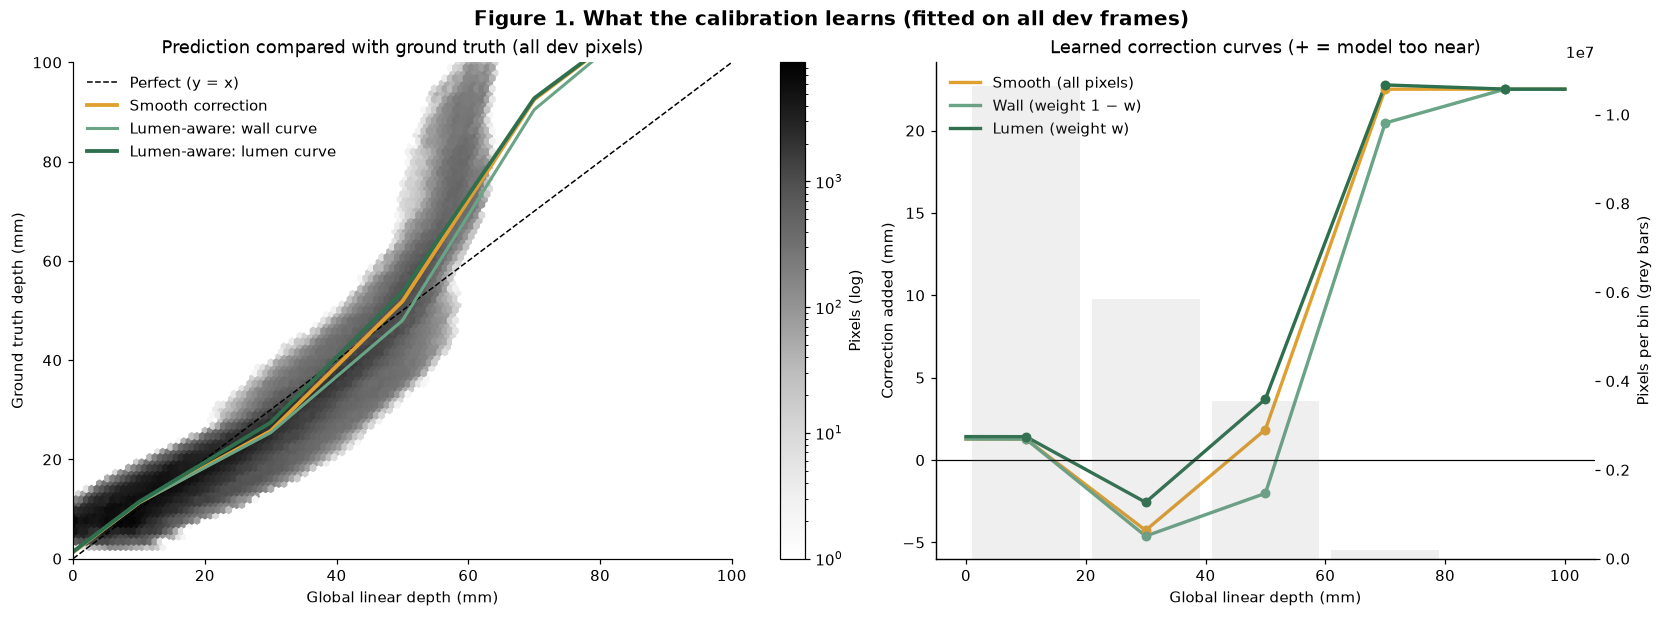

In [23]:
P_final = fit_all(list(range(len(FR))))           # fitted on all dev frames (used for the figure and the test)


def fig_calibration(P, fname="fig1_calibration_curves.png"):
    xs, ys = [], []
    for F in FR:
        v = F["valid"]
        xs.append(linear_depth(F, P)[v][::40])
        ys.append(F["gt"][v][::40])
    x, y = np.concatenate(xs), np.concatenate(ys)
    g = np.linspace(0, DMAX, 500)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    hb = axes[0].hexbin(x, y, gridsize=80, bins="log", cmap="Greys", mincnt=1)
    fig.colorbar(hb, ax=axes[0], label="Pixels (log)")
    axes[0].plot(g, g, "--", color="black", lw=1, label="Perfect (y = x)")
    axes[0].plot(g, g + np.interp(g, *P["curves"]["all"]), color=COLORS[SMO], lw=2.5, label="Smooth correction")
    axes[0].plot(g, g + np.interp(g, *P["curves"]["wall_both"]), color="#6aa486", lw=2, label="Lumen-aware: wall curve")
    axes[0].plot(g, g + np.interp(g, *P["curves"]["lumen_both"]), color="#2e6f4e", lw=2.5, label="Lumen-aware: lumen curve")
    axes[0].set(xlabel="Global linear depth (mm)", ylabel="Ground truth depth (mm)", xlim=(0, DMAX), ylim=(0, DMAX),
                title="Prediction compared with ground truth (all dev pixels)")
    axes[0].legend(frameon=False, loc="upper left")

    for name, color, lbl in [("all", COLORS[SMO], "Smooth (all pixels)"),
                             ("wall_both", "#6aa486", "Wall (weight 1 − w)"),
                             ("lumen_both", "#2e6f4e", "Lumen (weight w)")]:
        cx, cy = P["curves"][name]
        axes[1].plot(g, np.interp(g, cx, cy), color=color, lw=2.2, label=lbl)
        axes[1].scatter(cx, cy, color=color, s=30, zorder=3)
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set(xlabel="Global linear depth (mm)", ylabel="Correction added (mm)",
                title="Learned correction curves (+ = model too near)")
    ax2 = axes[1].twinx()
    ax2.bar(CENTERS, P["counts"]["all"], width=18, alpha=0.12, color="grey")
    ax2.set_ylabel("Pixels per bin (grey bars)"); ax2.spines["top"].set_visible(False)
    axes[1].legend(frameon=False, loc="upper left")
    fig.suptitle("Figure 1. What the calibration learns (fitted on all dev frames)", fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


fig_calibration(P_final)

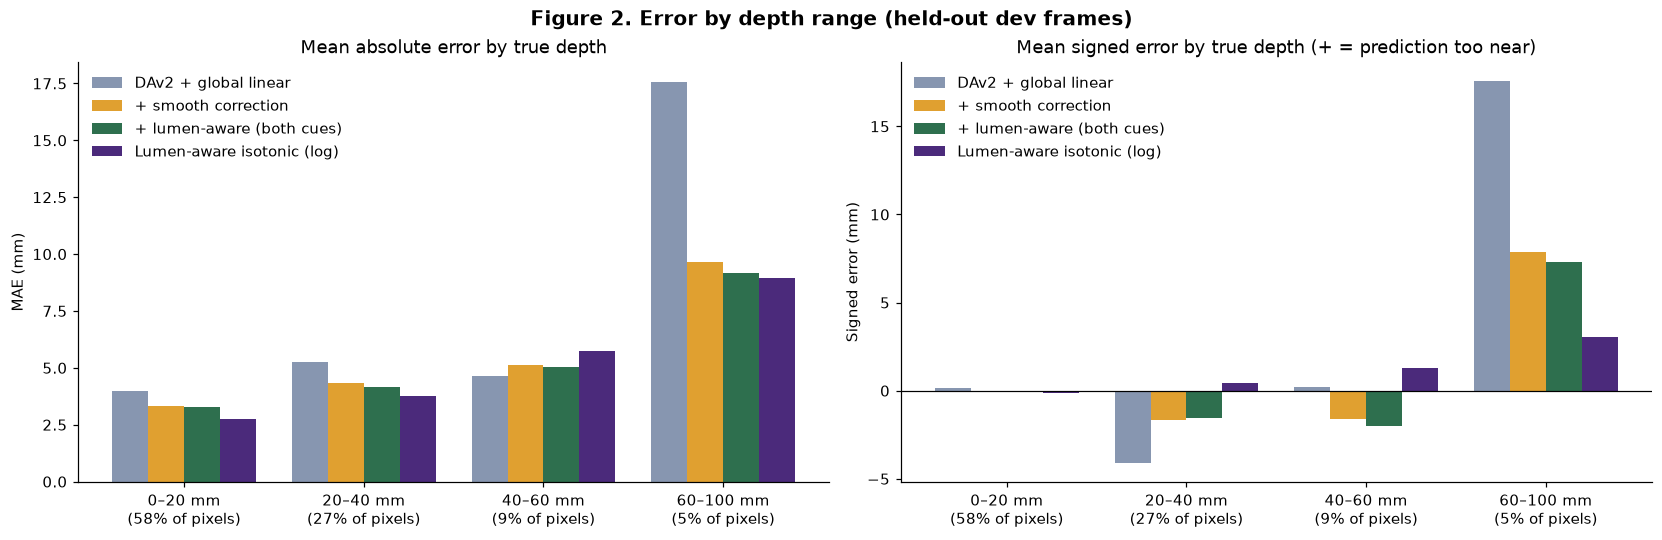

In [24]:
show_m = [LIN, SMO, LUM, FINAL]
labels_r = [f"{lo}–{hi}" for lo, hi in RANGES]
x = np.arange(len(RANGES)); wdt = 0.8 / len(show_m)
pix = range_acc[LIN][:, 2]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
for j, label in enumerate(show_m):
    acc = range_acc[label]
    off = x + (j - (len(show_m) - 1) / 2) * wdt
    axes[0].bar(off, acc[:, 0] / np.maximum(acc[:, 2], 1), wdt, color=COLORS[label], label=label)
    axes[1].bar(off, acc[:, 1] / np.maximum(acc[:, 2], 1), wdt, color=COLORS[label], label=label)
for a, ttl, yl in [(axes[0], "Mean absolute error by true depth", "MAE (mm)"),
                   (axes[1], "Mean signed error by true depth (+ = prediction too near)", "Signed error (mm)")]:
    a.set_xticks(x)
    a.set_xticklabels([f"{l} mm\n({p / pix.sum() * 100:.0f}% of pixels)" for l, p in zip(labels_r, pix)])
    a.set(title=ttl, ylabel=yl); a.legend(frameon=False)
axes[1].axhline(0, color="black", lw=0.8)
fig.suptitle("Figure 2. Error by depth range (held-out dev frames)", fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "fig2_error_by_depth_range.png", dpi=200, bbox_inches="tight"); plt.show()

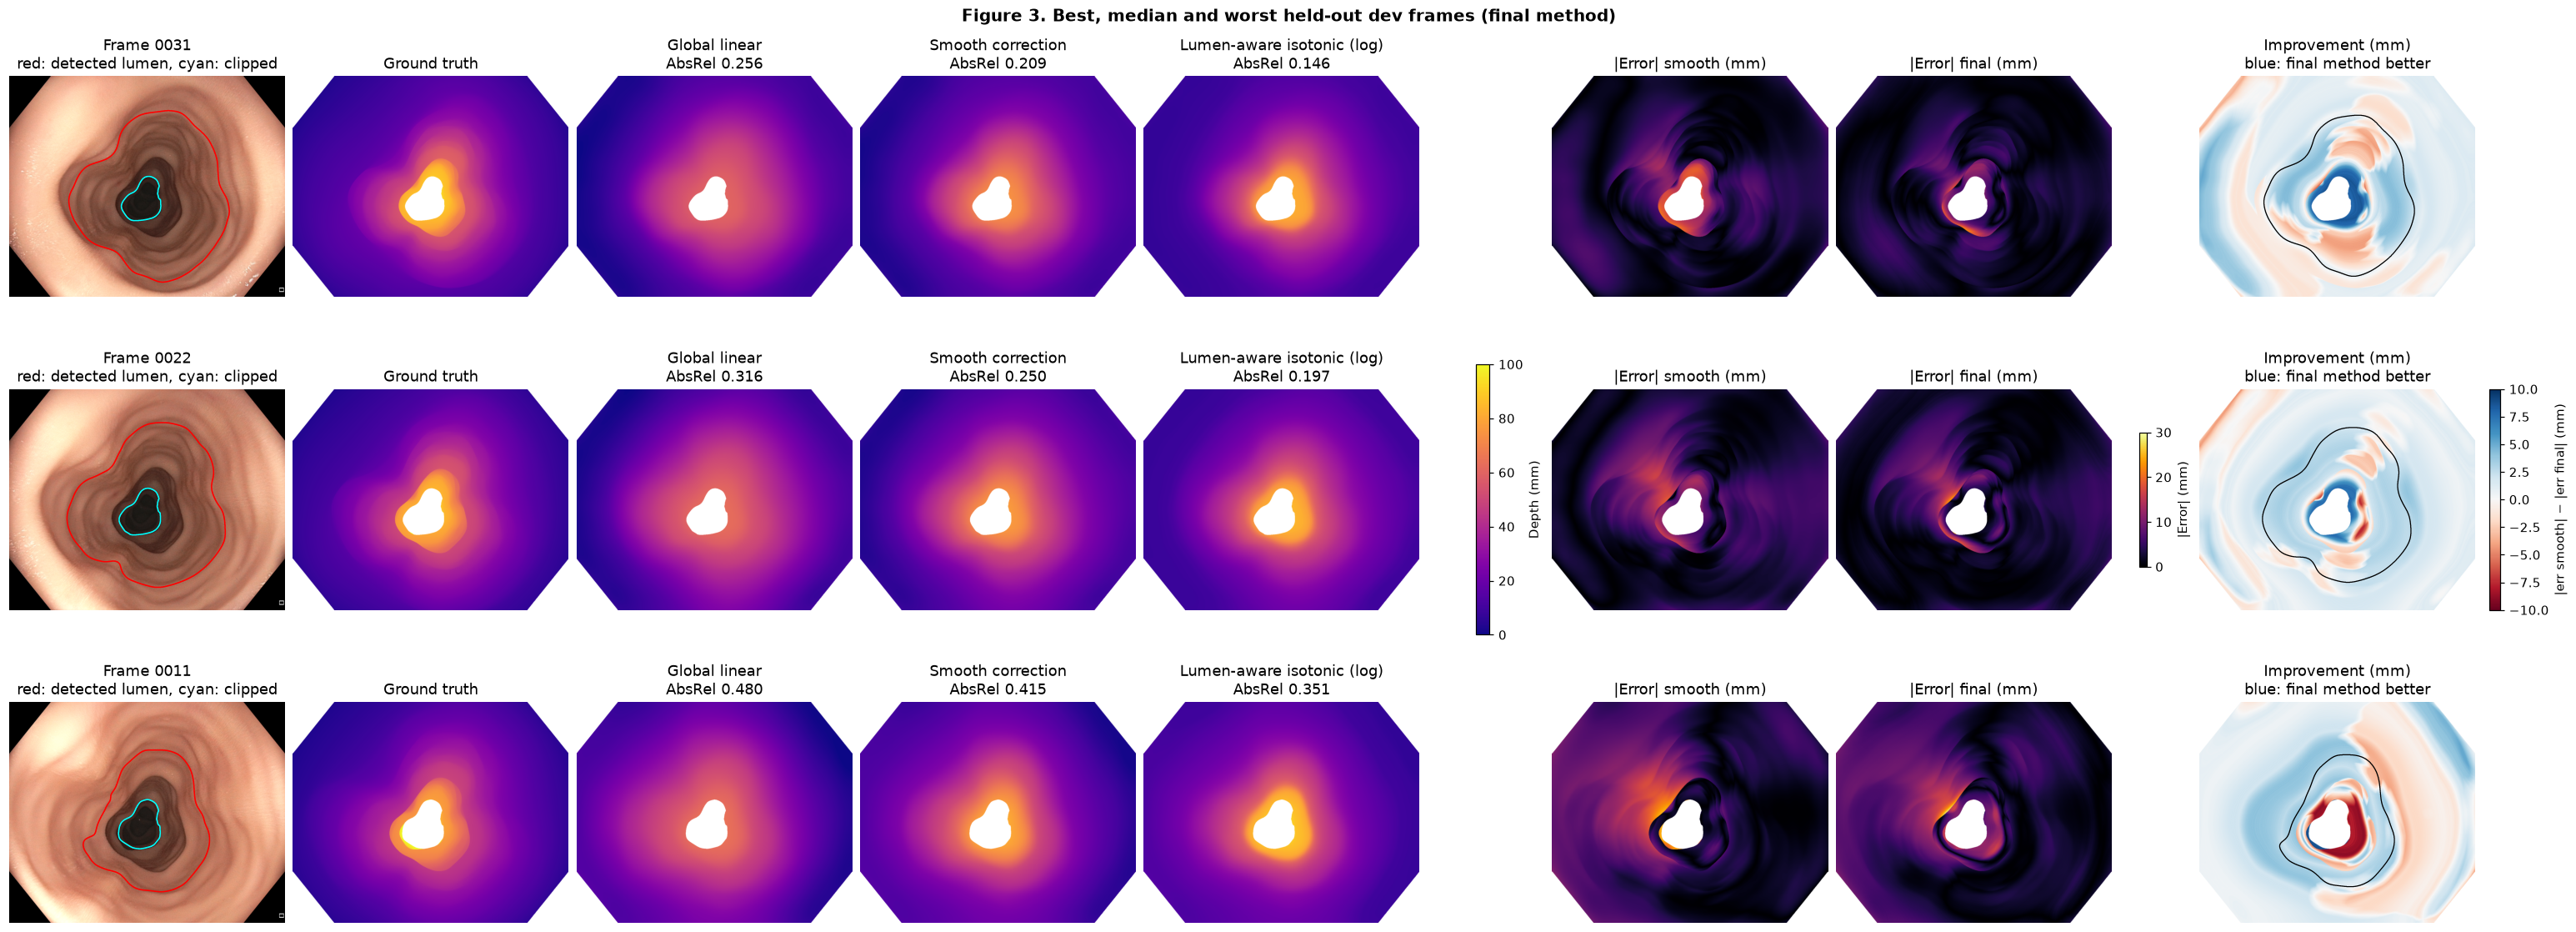

In [25]:
def nanv(a, F):
    return np.where(F["valid"], a, np.nan)


def fig_compare(idxs, fname="fig3_examples_best_median_worst.png"):
    fig, axes = plt.subplots(len(idxs), 8, figsize=(28, 3.5 * len(idxs)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idxs):
        F, P = FR[i], FOLD_PARAMS[HELD[i]]
        preds = {"lin": predict("linear", F, P), "sm": predict("smooth", F, P), "fin": predict("iso_lumen", F, P, "both")}
        ab = {n: frame_metrics(p, F)["absrel"] for n, p in preds.items()}
        es, ef = np.abs(preds["sm"] - F["gt"]), np.abs(preds["fin"] - F["gt"])
        ax = axes[r]
        ax[0].imshow(F["rgb"])
        ax[0].contour(F["core"], colors="red", linewidths=1)
        ax[0].contour(F["clipped"], colors="cyan", linewidths=1)
        ax[0].set_title(f"Frame {F['name']}\nred: detected lumen, cyan: clipped")
        for j, (d, t) in enumerate([(F["gt"], "Ground truth"),
                                    (preds["lin"], f"Global linear\nAbsRel {ab['lin']:.3f}"),
                                    (preds["sm"], f"Smooth correction\nAbsRel {ab['sm']:.3f}"),
                                    (preds["fin"], f"{FINAL}\nAbsRel {ab['fin']:.3f}")], start=1):
            im_d = ax[j].imshow(nanv(d, F), cmap="plasma", vmin=0, vmax=DMAX); ax[j].set_title(t)
        im_e = ax[5].imshow(nanv(es, F), cmap="inferno", vmin=0, vmax=30); ax[5].set_title("|Error| smooth (mm)")
        ax[6].imshow(nanv(ef, F), cmap="inferno", vmin=0, vmax=30); ax[6].set_title("|Error| final (mm)")
        im_i = ax[7].imshow(nanv(es - ef, F), cmap="RdBu", norm=TwoSlopeNorm(0, -10, 10))
        ax[7].contour(F["w"]["both"].astype(np.float32) > 0.5, colors="black", linewidths=0.8)
        ax[7].set_title("Improvement (mm)\nblue: final method better")
        for a in ax:
            a.axis("off")
    fig.colorbar(im_d, ax=axes[:, 1:5], fraction=0.012, label="Depth (mm)")
    fig.colorbar(im_e, ax=axes[:, 5:7], fraction=0.012, label="|Error| (mm)")
    fig.colorbar(im_i, ax=axes[:, 7], fraction=0.04, label="|err smooth| − |err final| (mm)")
    fig.suptitle("Figure 3. Best, median and worst held-out dev frames (final method)", fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


order = per_frame[per_frame.method == FINAL].set_index("idx").absrel.sort_values()
fig_compare([order.index[0], order.index[len(order) // 2], order.index[-1]])

In [26]:
TE = load_frames(test_paths, "Test frames")
print(f"Loaded {len(TE)} test frames from {test_paths[0].parent.name}")

# Oracle: one linear scale and shift fitted on the test sequence (uses test ground truth)
x = np.concatenate([-F["pred"][F["valid"]][::FIT_STRIDE] for F in TE]).astype(np.float64)
y = np.concatenate([F["gt"][F["valid"]][::FIT_STRIDE] for F in TE]).astype(np.float64)
a_or, b_or = np.polyfit(x, y, 1)
P_oracle = {"a": float(a_or), "b": float(b_or)}

ORACLE = "Oracle: linear fitted on test (not fair)"
test_rows = []
for F in TE:
    lumen_region = F["w"]["both"].astype(np.float32) > 0.5
    runs = [(label, predict(kind, F, P_final, cue or "both")) for label, kind, cue in METHODS]
    runs.append((ORACLE, predict("linear", F, P_oracle)))
    for label, pred in runs:
        m = frame_metrics(pred, F)
        if m is None:
            continue
        ml, mw = frame_metrics(pred, F, lumen_region), frame_metrics(pred, F, ~lumen_region)
        test_rows.append({"method": label, "frame": F["name"], **m,
                          "absrel_wall": mw["absrel"] if mw else np.nan,
                          "absrel_lumen": ml["absrel"] if ml else np.nan})

test_pf = pd.DataFrame(test_rows)
test_tab = (test_pf.groupby("method", sort=False)
            .agg(absrel=("absrel", "mean"), mse=("mse", "mean"), mae=("mae", "mean"), delta1=("delta1", "mean"),
                 absrel_wall=("absrel_wall", "mean"), absrel_lumen=("absrel_lumen", "mean"))
            .reset_index())
test_tab["rmse"] = np.sqrt(test_tab.pop("mse"))
test_pf.to_csv(out_dir / "per_frame_test.csv", index=False)
test_tab.to_csv(out_dir / "results_test.csv", index=False)

show_table(test_tab[["method", "absrel", "rmse", "mae", "delta1", "absrel_wall", "absrel_lumen"]],
           f"Table 2. Test results on trans_t2_b ({len(TE)} frames), parameters fitted on all dev frames")

T = test_tab.set_index("method")
print(f"Constant median -> final method : AbsRel {T.absrel['Constant median']:.3f} -> {T.absrel[FINAL]:.3f}")
print(f"Gain vs smooth on test          : lumen-aware {T.absrel[SMO] - T.absrel[LUM]:+.3f}, "
      f"final {T.absrel[SMO] - T.absrel[FINAL]:+.3f}")
print(f"Final method vs oracle          : {T.absrel[FINAL]:.3f} vs {T.absrel[ORACLE]:.3f}")
print(f"Scale and shift, dev fit        : a = {P_final['a']:.2f}, b = {P_final['b']:.2f}")
print(f"Scale and shift, test oracle    : a = {a_or:.2f}, b = {b_or:.2f}  (a large difference = domain shift)")

Test frames: 100%|██████████| 103/103 [00:54<00:00,  1.88it/s]


Loaded 103 test frames from trans_t2_b


Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓
Constant median,0.550,17.71,11.45,0.275,0.532,0.632
DAv2 + global linear,0.320,6.84,5.09,0.512,0.373,0.122
+ smooth correction,0.259,5.32,4.05,0.613,0.300,0.112
+ lumen-aware (darkness only),0.257,5.16,3.98,0.621,0.296,0.115
+ lumen-aware (depth only),0.258,5.29,4.03,0.613,0.298,0.112
+ lumen-aware (both cues),0.257,5.20,3.99,0.620,0.296,0.114
Isotonic (log),0.172,4.34,3.17,0.700,0.190,0.104
Lumen-aware isotonic (log),0.170,4.27,3.11,0.706,0.188,0.101
Oracle: linear fitted on test (not fair),0.274,6.75,4.70,0.551,0.313,0.126


Constant median -> final method : AbsRel 0.550 -> 0.170
Gain vs smooth on test          : lumen-aware +0.003, final +0.090
Final method vs oracle          : 0.170 vs 0.274
Scale and shift, dev fit        : a = 13.32, b = 65.11
Scale and shift, test oracle    : a = 11.85, b = 61.33  (a large difference = domain shift)


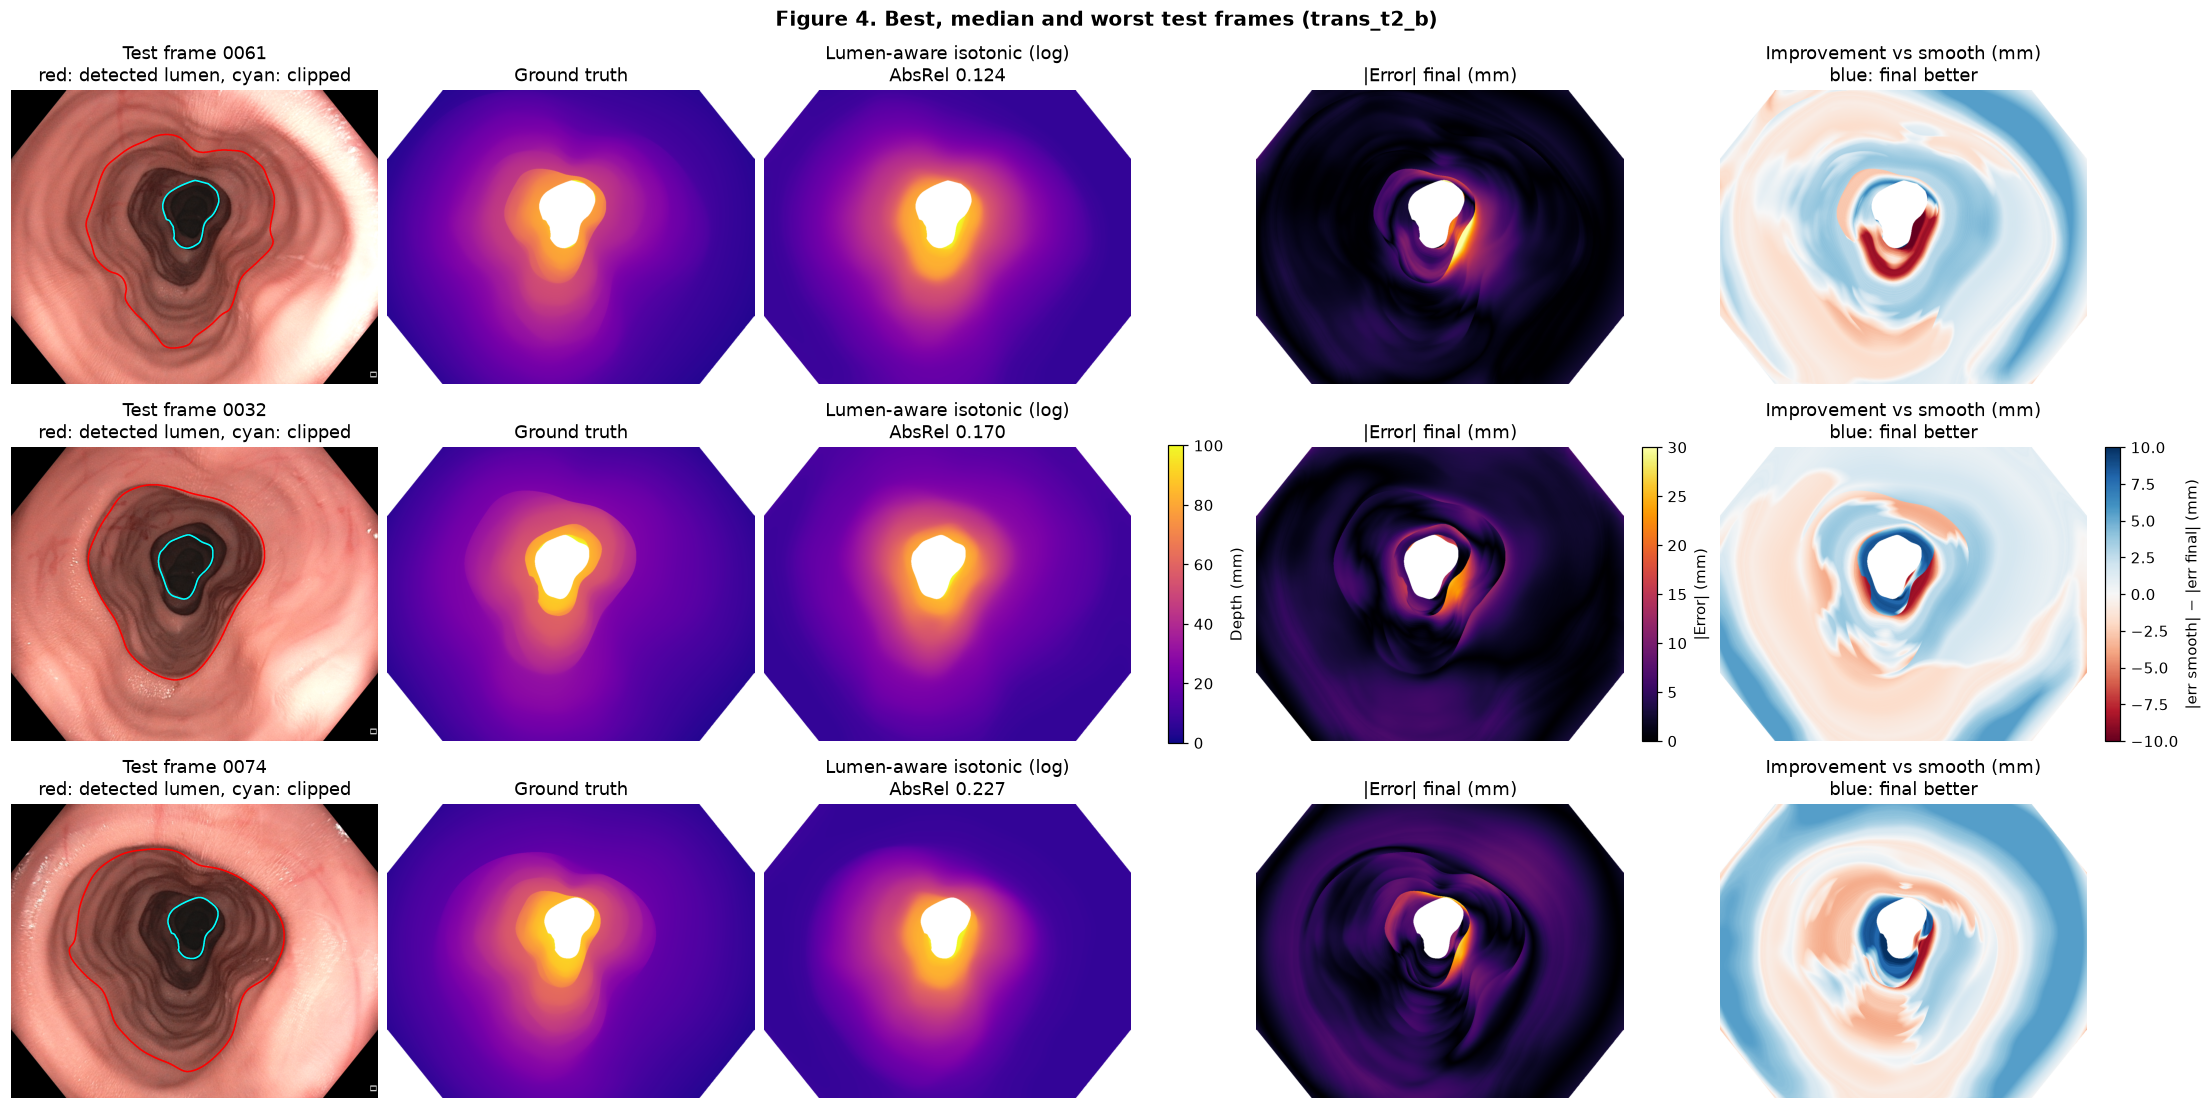

In [27]:
order_t = test_pf[test_pf.method == FINAL].set_index("frame").absrel.sort_values()
pick = [order_t.index[0], order_t.index[len(order_t) // 2], order_t.index[-1]]
name_to_F = {F["name"]: F for F in TE}

fig, axes = plt.subplots(3, 5, figsize=(20, 10), constrained_layout=True)
for r, nm in enumerate(pick):
    F = name_to_F[nm]
    sm, fin = predict("smooth", F, P_final), predict("iso_lumen", F, P_final, "both")
    axes[r, 0].imshow(F["rgb"])
    axes[r, 0].contour(F["core"], colors="red", linewidths=1)
    axes[r, 0].contour(F["clipped"], colors="cyan", linewidths=1)
    axes[r, 0].set_title(f"Test frame {nm}\nred: detected lumen, cyan: clipped")
    im = axes[r, 1].imshow(np.where(F["valid"], F["gt"], np.nan), cmap="plasma", vmin=0, vmax=DMAX)
    axes[r, 1].set_title("Ground truth")
    axes[r, 2].imshow(np.where(F["valid"], fin, np.nan), cmap="plasma", vmin=0, vmax=DMAX)
    axes[r, 2].set_title(f"{FINAL}\nAbsRel {frame_metrics(fin, F)['absrel']:.3f}")
    ie = axes[r, 3].imshow(np.where(F["valid"], np.abs(fin - F["gt"]), np.nan), cmap="inferno", vmin=0, vmax=30)
    axes[r, 3].set_title("|Error| final (mm)")
    ii = axes[r, 4].imshow(np.where(F["valid"], np.abs(sm - F["gt"]) - np.abs(fin - F["gt"]), np.nan),
                           cmap="RdBu", norm=TwoSlopeNorm(0, -10, 10))
    axes[r, 4].set_title("Improvement vs smooth (mm)\nblue: final better")
    for a in axes[r]:
        a.axis("off")
fig.colorbar(im, ax=axes[:, 1:3], fraction=0.02, label="Depth (mm)")
fig.colorbar(ie, ax=axes[:, 3], fraction=0.04, label="|Error| (mm)")
fig.colorbar(ii, ax=axes[:, 4], fraction=0.04, label="|err smooth| − |err final| (mm)")
fig.suptitle("Figure 4. Best, median and worst test frames (trans_t2_b)", fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "fig4_test_examples.png", dpi=200, bbox_inches="tight"); plt.show()

In [28]:
def normalise(pred, fov, how):
    if how == "none":
        return pred
    v = pred[fov]
    if how == "median":
        return pred / np.median(v)
    lo, hi = np.percentile(v, [5, 95])
    return (pred - lo) / (hi - lo + 1e-6)


def set_predictions(preds):
    for F, p in zip(FR, preds):
        F["pred"] = p.astype(np.float32)
        make_lumen_maps(F)


SENS_METHODS = [m for m in METHODS if m[0] in (SMO, LUM, FINAL)]
SETTINGS = [("Input", "518x644",        lambda F, p: predict_disp(F["rgb"], (518, 644), False)),
            ("Input", "518x644 + flip", lambda F, p: predict_disp(F["rgb"], (518, 644), True)),
            ("Input", "700x868",        lambda F, p: predict_disp(F["rgb"], (700, 868), False)),
            ("Input", "700x868 + flip", lambda F, p: predict_disp(F["rgb"], (700, 868), True)),
            ("Normalisation", "median", lambda F, p: normalise(p, F["fov"], "median")),
            ("Normalisation", "range",  lambda F, p: normalise(p, F["fov"], "range"))]

rows = []
try:
    for group, name, make in SETTINGS:
        set_predictions([make(F, p) for F, p in zip(FR, BASE_PRED)])
        s = summarise(evaluate(SENS_METHODS, with_train=False)[0]).set_index("method").absrel
        rows.append({"Check": group, "Setting": name, **{f"AbsRel {m}": s[m] for m in (SMO, LUM, FINAL)}})
finally:
    set_predictions(BASE_PRED)

sens = pd.DataFrame(rows)
sens.to_csv(out_dir / "sensitivity.csv", index=False)
display(sens.style.format({c: "{:.3f}" for c in sens.columns if c.startswith("AbsRel")})
        .hide(axis="index").set_caption("Table 3. Sensitivity of held-out dev AbsRel to the input settings")
        .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold; text-align: left;"},
                           {"selector": "th, td", "props": "padding: 4px 12px; text-align: left;"}]))

Evaluating: 100%|██████████| 4/4 [00:10<00:00,  2.56s/it]


Check,Setting,AbsRel + smooth correction,AbsRel + lumen-aware (both cues),AbsRel Lumen-aware isotonic (log)
Input,518x644,0.271,0.266,0.224
Input,518x644 + flip,0.266,0.262,0.221
Input,700x868,0.247,0.243,0.209
Input,700x868 + flip,0.258,0.254,0.208
Normalisation,median,0.266,0.264,0.193
Normalisation,range,0.242,0.239,0.206


In [29]:
to_list = lambda t: [np.asarray(t[0]).tolist(), np.asarray(t[1]).tolist()]
iso_to_dict = lambda m: {"x": m.X_thresholds_.tolist(), "log_depth": m.y_thresholds_.tolist()}
with open(out_dir / "final_params_dev.json", "w") as f:
    json.dump({"model": MODEL_ID, "mask": MASK, "input_size": INPUT_SIZE, "sigma": SIGMA, "tau": TAU,
               "bin_edges": BIN_EDGES.tolist(), "a": P_final["a"], "b": P_final["b"], "median": P_final["median"],
               "curves": {k: to_list(v) for k, v in P_final["curves"].items()},
               "isotonic": {"all": iso_to_dict(P_final["iso"]["all"]),
                            "wall": iso_to_dict(P_final["iso_lumen"]["wall"]),
                            "lumen": iso_to_dict(P_final["iso_lumen"]["lumen"])}}, f, indent=2)

save_summary([{"model": f"DAv2 Small {r.method}", "output_type": "disparity",
               "alignment": "global_lsq" if r.method != "Constant median" else "none",
               "fit_on": "dev_blocks_cv", "split": "dev", "n_frames": len(FR),
               "absrel": r.absrel, "rmse": r.rmse, "mae": r.mae, "delta1": r.delta1}
              for r in abl.itertuples()] +
             [{"model": f"DAv2 Small {r.method}", "output_type": "disparity",
               "alignment": "test_lsq_oracle" if r.method == ORACLE else ("none" if r.method == "Constant median" else "global_lsq"),
               "fit_on": "test" if r.method == ORACLE else "dev_all", "split": "test", "n_frames": len(TE),
               "absrel": r.absrel, "rmse": r.rmse, "mae": r.mae, "delta1": r.delta1}
              for r in test_tab.itertuples()], out_dir, RUN_NAME)
save_run_info(out_dir, DEVICE, SEED, extra={"model": MODEL_ID, "mask": MASK, "input_size": INPUT_SIZE,
                                             "sigma": SIGMA, "tau": TAU, "n_blocks": N_BLOCKS, "gap": GAP})
print(f"Saved results to {out_dir}")

Saved results to /Users/aditiraghu/c3vd/results/Final_LumenAware_DAv2_Small_exclude_clipped
